# Лабораторна робота № 7 — відтворювана структура ML-проєкту

Ковальчук · ІПЗс-24-1 · варіант 5 · викладач Бедратюк Л.П.

Notebook лише **користується** пакетом `ml_project` (описати, передбачити, показати помилки, відтворити число); компонент не залежить
від цього notebook. Усі числа нижче обчислюються тут або читаються зі звітів, створених `build_artifacts.py`.
Model selection не виконується: family, параметри, поріг і ознаки заморожені в ЛР № 6.

In [1]:
import json, sys, tempfile, unittest, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if (Path.cwd().parent / "configs").is_dir() else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from ml_project.config import load_project_config
from ml_project.errors import ProjectError
from ml_project.predictor import ProjectPredictor
from ml_project.train import rebuild_model

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
config = load_project_config(ROOT / "configs" / "project_config.json")
predictor = ProjectPredictor(config)
example = json.loads((ROOT / "configs" / "inference_example.json").read_text(encoding="utf-8"))
print("python", sys.version.split()[0], "| threshold", config.threshold, "| tolerance", config.probability_tolerance)

python 3.12.0 | threshold 0.5 | tolerance 1e-12


## 1. Приймання handoff ЛР № 6 і межі змін

Нижче — результат перевірок з `reports/handoff_acceptance.json` (створює `build_artifacts.py`). Відсутній у handoff контрольний хеш
моделі **не відновлювався з пам'яті**: модель прийнято за незалежними доказами — байти збігаються з `lab06/results/models/automl.joblib`,
а контрольні ймовірності відтворюються.

In [2]:
acc = json.loads((ROOT / "reports" / "handoff_acceptance.json").read_text(encoding="utf-8"))
checks = pd.DataFrame({"check": list(acc["checks"]), "result": [str(v) for v in acc["checks"].values()]})
print(checks.to_string(index=False))
print()
print("files present:", sum(f["present"] for f in acc["files"].values()), "of", len(acc["files"]))
print("gaps:", acc["gaps"])
print("control reproduction max |dp| from the handoff model:", acc["control_reproduction_max_abs_diff"])

                                     check result
 decision_sha_matches_decision_sha256_file   True
         test_metrics_decision_sha_matches   True
              decision_has_no_test_metrics   True
decision_config_sha_matches_handoff_config   True
    model_bytes_equal_lab06_results_automl   True
             split_ids_unique_and_complete   True
           test_count_matches_test_metrics   True
  test_positive_count_matches_test_metrics   True
         schema_range_equals_train_min_max   True
      schema_range_equals_all_data_min_max  False

files present: 14 of 14
gaps: ['model checksum (sha256 of pipeline.joblib): absent (handoff only hashes the decision record)']
control reproduction max |dp| from the handoff model: 0.0


## 2. Опис компонента і контрольний прогноз

`describe()` повертає лише дані користувача (версії, хеші, 30 ознак, клас, поріг) — без sklearn-об'єктів і шляхів.
Контрольний прогноз порівнюється з очікуванням з handoff із допуском, обраним до запуску (`1e-12`).

In [3]:
d = predictor.describe()
print({k: d[k] for k in ["model_version", "schema_version", "n_features", "positive_class", "threshold", "family", "candidate_id", "max_batch_size"]})
print("model_sha256:", d["model_sha256"])
rows = []
for i, (rec, exp) in enumerate(zip(example["records"], example["expected_probability"])):
    out = predictor.predict_record(rec)
    rows.append({"record": i, "probability": out["probability"], "expected": exp,
                 "abs_diff": abs(out["probability"] - exp), "class": out["predicted_class"], "warnings": len(out["warnings"])})
control = pd.DataFrame(rows)
print(control.to_string(index=False))
assert (control.abs_diff <= config.probability_tolerance).all()
print("keys of one response:", sorted(predictor.predict_record(example["record"])))

{'model_version': '1.0.0', 'schema_version': '1.0', 'n_features': 30, 'positive_class': 'malignant', 'threshold': 0.5, 'family': 'lrl2', 'candidate_id': 'automl_seed42_trial10', 'max_batch_size': 1000}
model_sha256: b63381332edb446557779d0d3042cd4e3be973cbc9fd70a1682513fe9abc315b
 record  probability  expected     abs_diff     class  warnings
      0     0.716876  0.716876 0.000000e+00 malignant         0
      1     0.010617  0.010617 8.673617e-18    benign         0
      2     0.014847  0.014847 0.000000e+00    benign         0
keys of one response: ['model_version', 'positive_class', 'predicted_class', 'probability', 'schema_version', 'threshold', 'warnings']


## 3. Контракт входу: що блокується і що лише попереджає

Кожен випадок — окремий запис; помилки контрольовані (клас винятку + повідомлення), а не traceback.
Значення поза train-діапазоном проходить із `warnings`.

In [4]:
base = example["record"]
cases = {
    "valid": base,
    "reordered keys": dict(reversed(list(base.items()))),
    "missing area_mean": {k: v for k, v in base.items() if k != "area_mean"},
    "extra field id": {**base, "id": 7},
    "string '12.3'": {**base, "radius_mean": "12.3"},
    "bool True": {**base, "radius_mean": True},
    "NaN": {**base, "radius_mean": float("nan")},
    "+inf": {**base, "radius_mean": float("inf")},
    "negative": {**base, "radius_mean": -1.0},
    "1e308 (overflow)": {**base, "smoothness_mean": 1e308},
    "out of train range": {**base, "radius_mean": 40.0},
}
table = []
for name, rec in cases.items():
    try:
        out = predictor.predict_record(rec)
        table.append({"case": name, "outcome": "predicted", "detail": f"p={out['probability']:.6f}, warnings={len(out['warnings'])}"})
    except ProjectError as exc:
        table.append({"case": name, "outcome": type(exc).__name__, "detail": str(exc)})
print(pd.DataFrame(table).to_string(index=False))
assert predictor.predict_record(cases["reordered keys"])["probability"] == predictor.predict_record(base)["probability"]
print()
print("warning text:", predictor.predict_record(cases["out of train range"])["warnings"])

              case              outcome                                                           detail
             valid            predicted                                           p=0.716876, warnings=0
    reordered keys            predicted                                           p=0.716876, warnings=0
 missing area_mean InputValidationError                                      missing features: area_mean
    extra field id InputValidationError                                          unexpected features: id
     string '12.3' InputValidationError                    feature radius_mean must be a number, got str
         bool True InputValidationError                   feature radius_mean must be a number, got bool
               NaN InputValidationError                               feature radius_mean must be finite
              +inf InputValidationError                               feature radius_mean must be finite
          negative InputValidationError                

## 4. Rebuild і числова відтворюваність

`rebuild_model` перенавчає **ту саму** frozen-конфігурацію на тих самих 455 train ID (без пошуку) у тимчасовий файл і порівнює з переданою моделлю.
Test ID використовуються лише для перерахунку вже відомої метрики AP.

In [5]:
with tempfile.TemporaryDirectory() as tmp:
    rep = rebuild_model(ROOT, Path(tmp) / "rebuilt.joblib")
summary = {
    "n_train / n_test": (rep["n_train"], rep["n_test"]),
    "max |dp| control (saved vs rebuilt)": rep["control_records"]["max_abs_diff_saved_vs_rebuilt"],
    "max |dp| test 114": rep["max_abs_diff_saved_vs_rebuilt_test"],
    "max |dp| all 569": rep["max_abs_diff_saved_vs_rebuilt_all569"],
    "max |dcoef|": rep["max_abs_diff_coef"],
    "test AP lab06 / saved / rebuilt": (rep["test_ap"]["reference_lab06"], rep["test_ap"]["saved"], rep["test_ap"]["rebuilt"]),
    "confusion matrix rebuilt": rep["test_confusion_matrix"]["rebuilt"],
    "file bytes identical": rep["byte_identical_file"],
    "passed": rep["passed"],
}
for k, v in summary.items():
    print(f"{k}: {v}")
saved_report = json.loads((ROOT / "reports" / "reproducibility.json").read_text(encoding="utf-8"))
assert saved_report["max_abs_diff_saved_vs_rebuilt_test"] == rep["max_abs_diff_saved_vs_rebuilt_test"]

n_train / n_test: (455, 114)
max |dp| control (saved vs rebuilt): 0.0
max |dp| test 114: 0.0
max |dp| all 569: 0.0
max |dcoef|: 0.0
test AP lab06 / saved / rebuilt: (0.9965986394557824, 0.9965986394557824, 0.9965986394557824)
confusion matrix rebuilt: [[72, 0], [2, 40]]
file bytes identical: False
passed: True


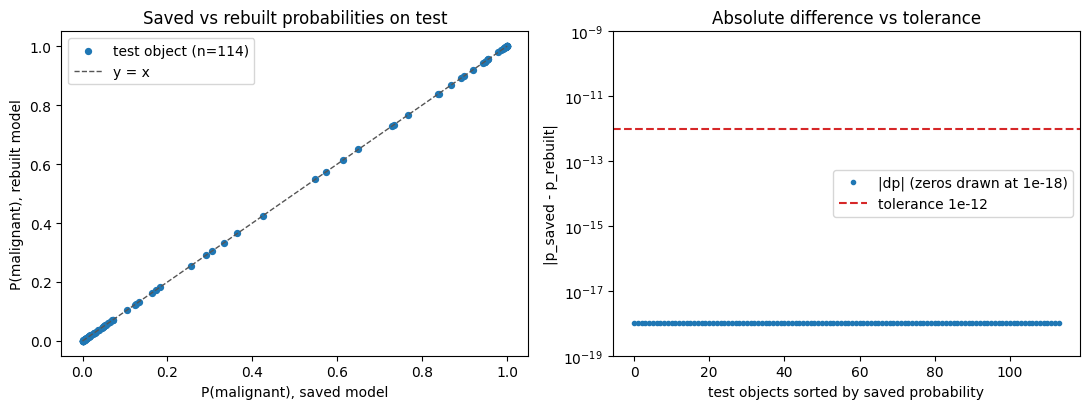

max |dp| on test: 0.0


In [6]:
from sklearn.datasets import load_breast_cancer
raw = load_breast_cancer()
split = pd.read_csv(ROOT / "data" / "split_ids.csv")
test_ids = split.loc[split.part == "test", "id"].to_numpy()
X_test = raw.data[test_ids]
p_saved = predictor.model_probabilities(X_test)
with tempfile.TemporaryDirectory() as tmp:
    import joblib
    rebuild_model(ROOT, Path(tmp) / "r.joblib")
    p_new = joblib.load(Path(tmp) / "r.joblib").predict_proba(X_test)[:, 1]
diff = np.abs(p_saved - p_new)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(p_saved, p_new, s=18, color="#1f77b4", label="test object (n=114)")
ax[0].plot([0, 1], [0, 1], color="#555", lw=1, ls="--", label="y = x")
ax[0].set_xlabel("P(malignant), saved model"); ax[0].set_ylabel("P(malignant), rebuilt model")
ax[0].set_title("Saved vs rebuilt probabilities on test"); ax[0].legend()
order = np.argsort(p_saved)
ax[1].semilogy(np.arange(len(diff)), np.maximum(diff[order], 1e-18), ".", color="#1f77b4", label="|dp| (zeros drawn at 1e-18)")
ax[1].axhline(config.probability_tolerance, color="#d62728", ls="--", label=f"tolerance {config.probability_tolerance:g}")
ax[1].set_ylim(1e-19, 1e-9)
ax[1].set_xlabel("test objects sorted by saved probability"); ax[1].set_ylabel("|p_saved - p_rebuilt|")
ax[1].set_title("Absolute difference vs tolerance"); ax[1].legend(loc="center right")
fig.tight_layout(); fig.savefig(FIG / "fig1_saved_vs_rebuilt.png", dpi=120); plt.show()
print("max |dp| on test:", float(diff.max()))

**Інтерпретація рис. 1.** Усі 114 точок лежать на діагоналі, а різниця дорівнює нулю (на логарифмічній осі нулі намальовано як 1e-18), тобто
не перевищує допуск 1e-12 з великим запасом. Це **числова**, а не побайтова еквівалентність: файли `joblib` мають різні хеші.
Допуск 1e-12 застосовний лише до детермінованої однопотокової LR в однаковому середовищі.

## 5. Попередження поза train-діапазоном

Крива показує, як зміна однієї ознаки (`radius_mean`) виводить значення за train min/max. Попередження не блокує прогноз, але сигналізує
про екстраполяцію; зелена зона — діапазон, у якому модель бачила дані.

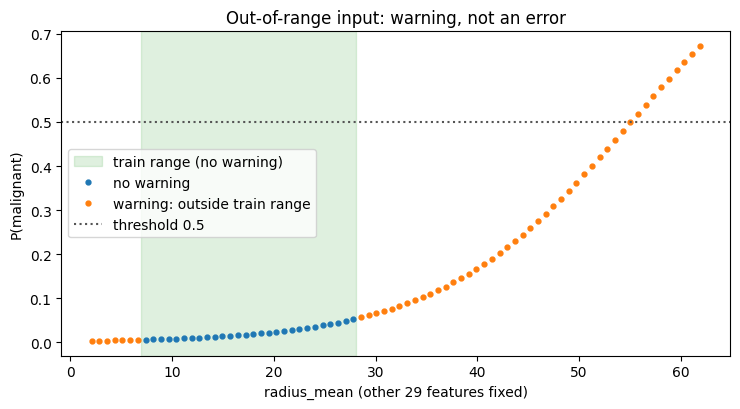

warnings fire exactly outside the range: True
warned points: 52 of 80
threshold 0.5 is first crossed at radius_mean = 55.8 (train max 28.11, ratio 1.98)


In [7]:
lo, hi = [(f["min"], f["max"]) for f in json.loads((ROOT / "configs" / "schema.json").read_text(encoding="utf-8"))["features"] if f["name"] == "radius_mean"][0]
grid = np.linspace(0.3 * lo, 2.2 * hi, 80)
probs, warned = [], []
for v in grid:
    out = predictor.predict_record({**example["records"][1], "radius_mean": float(v)})
    probs.append(out["probability"]); warned.append(bool(out["warnings"]))
probs, warned = np.array(probs), np.array(warned)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axvspan(lo, hi, color="#2ca02c", alpha=0.15, label="train range (no warning)")
ax.plot(grid[~warned], probs[~warned], "o", ms=3.5, color="#1f77b4", label="no warning")
ax.plot(grid[warned], probs[warned], "o", ms=3.5, color="#ff7f0e", label="warning: outside train range")
ax.axhline(config.threshold, color="#555", ls=":", label="threshold 0.5")
ax.set_xlabel("radius_mean (other 29 features fixed)"); ax.set_ylabel("P(malignant)")
ax.set_title("Out-of-range input: warning, not an error"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig2_out_of_range_warning.png", dpi=120); plt.show()
print("warnings fire exactly outside the range:", bool(np.all(warned == ((grid < lo) | (grid > hi)))))
print("warned points:", int(warned.sum()), "of", len(grid))
cross = grid[probs >= config.threshold][0]
print(f"threshold 0.5 is first crossed at radius_mean = {cross:.1f} (train max {hi}, ratio {cross / hi:.2f})")

**Інтерпретація рис. 2.** Для запису 1 (у train-діапазоні P(malignant) ≈ 0.01) ймовірність плавно зростає зі збільшенням `radius_mean`
і перетинає поріг 0.5 лише далеко за train max (значення надруковано вище). Усю цю ділянку компонент позначає попередженням, а прогноз
видає: це лінійна екстраполяція, а не доказ того, що запис справді malignant. Попередження збігаються з виходом за [min, max] точно
(перевірка вище), тому в ЛР № 8 їх можна використати як сигнал дрейфу, але вони не доводять, що прогноз хибний.

## 6. Автоматичні тести

Нижче підраховано тести за групами (без повторного запуску: повний запуск ~1 хв, результат записано в `reports/test_results.txt`).

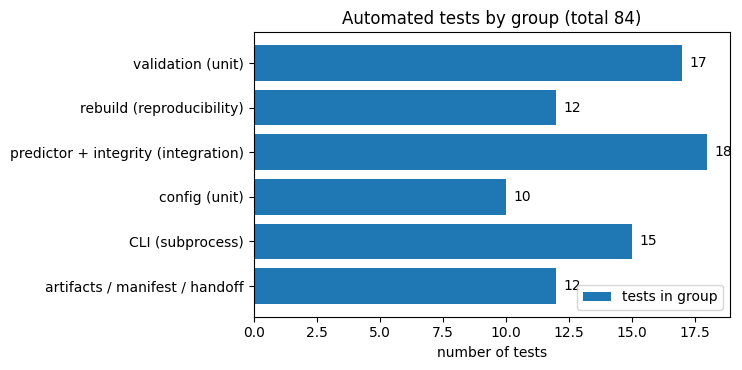

collected: 84 | recorded run: ['Ran 84 tests in 79.548s', 'OK']


In [8]:
loader = unittest.TestLoader()
suite = loader.discover(str(ROOT / "tests"), top_level_dir=str(ROOT / "tests"))
def flatten(s):
    for t in s:
        if isinstance(t, unittest.TestSuite):
            yield from flatten(t)
        else:
            yield t
counts = {}
for t in flatten(suite):
    counts[type(t).__module__] = counts.get(type(t).__module__, 0) + 1
counts = dict(sorted(counts.items()))
labels = {"test_config": "config (unit)", "test_validation": "validation (unit)", "test_predictor": "predictor + integrity (integration)",
          "test_cli": "CLI (subprocess)", "test_rebuild": "rebuild (reproducibility)", "test_artifacts": "artifacts / manifest / handoff"}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.barh([labels.get(k, k) for k in counts], list(counts.values()), color="#1f77b4", label="tests in group")
for b, v in zip(bars, counts.values()):
    ax.text(v + 0.3, b.get_y() + b.get_height() / 2, str(v), va="center")
ax.set_xlabel("number of tests"); ax.set_title(f"Automated tests by group (total {sum(counts.values())})"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig3_test_groups.png", dpi=120); plt.show()
summary_lines = [l for l in (ROOT / "reports" / "test_results.txt").read_text(encoding="utf-8").splitlines() if l.startswith(("Ran", "OK", "FAILED"))]
print("collected:", sum(counts.values()), "| recorded run:", summary_lines)
assert f"Ran {sum(counts.values())} tests" in summary_lines[0]

**Інтерпретація рис. 3.** Найбільше перевірок у групах валідатора та CLI, бо саме там контракт найчастіше порушується; rebuild і артефакти
мають менше тестів, але кожен перевіряє окремий інваріант (train ID, цільова мітка, хеш). Кількість у заголовку збігається із записаним запуском.

## 7. Висновок

Компонент завантажується з конфігурації, перевіряє SHA-256 моделі **до** десеріалізації, відхиляє порушення контракту контрольованими помилками
і відтворює контрольний прогноз та test AP без повторного вибору моделі. Він ще не production-ready: немає HTTP-шару, моніторингу, захисту від навантаження;
повний інженерний висновок і гарантії для ЛР № 8 — у `README.md`.